In [1]:
!pip install -q pandas matplotlib seaborn opencv-python scikit-learn
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import hashlib
import pathlib as Path
import zipfile
import cv2
from sklearn.model_selection import train_test_split
from PIL import Image
import random
from glob import glob
from collections import defaultdict
from collections import Counter
from torchvision import transforms
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, array_to_img

Mounted at /content/drive


In [2]:
import shutil
import zipfile

# Set base path
base_path = "/content/drive/MyDrive/A2_Machine_Learning/"

# Define extraction paths
train_zip_path = os.path.join(base_path, "train_images.zip")
test_zip_path = os.path.join(base_path, "test_images.zip")

train_extract_path = os.path.join(base_path, "train_images")
test_extract_path = os.path.join(base_path, "test_images")

# Function to clean and extract
def clean_and_extract(zip_path, extract_path, label):
    if os.path.exists(extract_path):
        print(f"🗑️  Removing existing folder: {extract_path}")
        shutil.rmtree(extract_path)

    print(f"📦 Extracting {label} images from {zip_path} to {extract_path}")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"✅ Extraction done for {label} images.\n")

# Perform for both train and test
clean_and_extract(train_zip_path, train_extract_path, "Train")
clean_and_extract(test_zip_path, test_extract_path, "Test")


🗑️  Removing existing folder: /content/drive/MyDrive/A2_Machine_Learning/train_images
📦 Extracting Train images from /content/drive/MyDrive/A2_Machine_Learning/train_images.zip to /content/drive/MyDrive/A2_Machine_Learning/train_images
✅ Extraction done for Train images.

🗑️  Removing existing folder: /content/drive/MyDrive/A2_Machine_Learning/test_images
📦 Extracting Test images from /content/drive/MyDrive/A2_Machine_Learning/test_images.zip to /content/drive/MyDrive/A2_Machine_Learning/test_images
✅ Extraction done for Test images.



In [3]:
# Read meta_train.csv
meta = pd.read_csv('/content/drive/MyDrive/A2_Machine_Learning/meta_train.csv')

# Display the first few rows
meta.head()

,image_id,label,variety,age
0,100330.jpg,bacterial_leaf_blight,ADT45,45
1,100365.jpg,bacterial_leaf_blight,ADT45,45
2,100382.jpg,bacterial_leaf_blight,ADT45,45
3,100632.jpg,bacterial_leaf_blight,ADT45,45
4,101918.jpg,bacterial_leaf_blight,ADT45,45


In [4]:
# Dataset shape
print(f"Number of rows: {meta.shape[0]}")
print(f"Number of columns: {meta.shape[1]}")

# General info
meta.info()

# Basic statistics
meta.describe()

Number of rows: 10407
Number of columns: 4
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10407 entries, 0 to 10406
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   image_id  10407 non-null  object
 1   label     10407 non-null  object
 2   variety   10407 non-null  object
 3   age       10407 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 325.3+ KB


,age
count,10407.000000
mean,64.043624
std,8.958830
min,45.000000
25%,60.000000
50%,67.000000
75%,70.000000
max,82.000000


In [5]:
# Check for missing values
meta.isnull().sum()


,0
image_id,0
label,0
variety,0
age,0


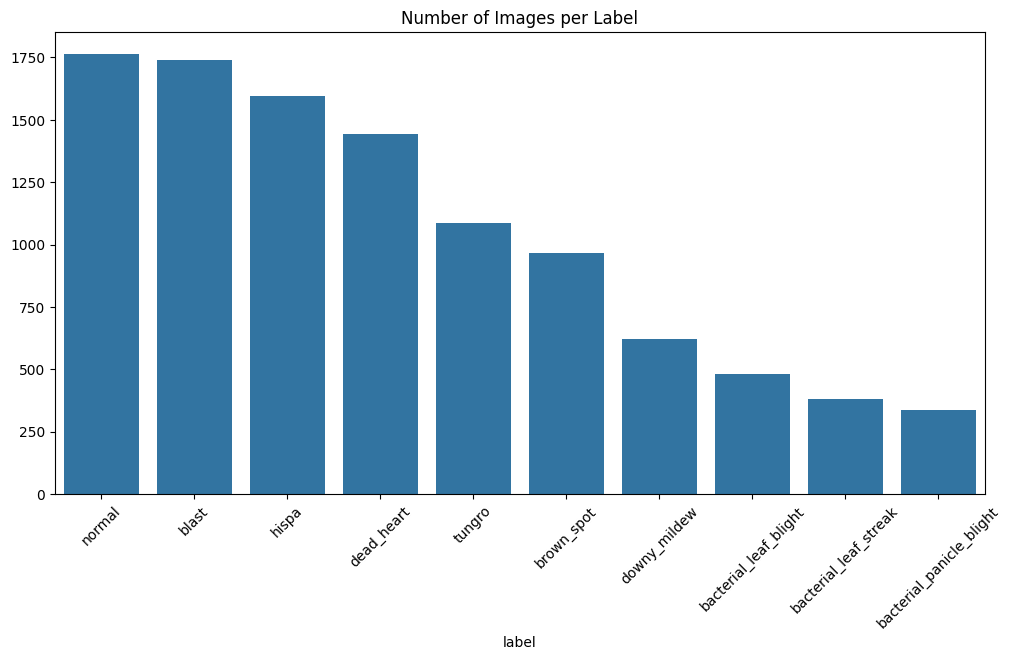

In [6]:
# Count images per label
label_counts = meta['label'].value_counts()

# Plot
plt.figure(figsize=(12,6))
sns.barplot(x=label_counts.index, y=label_counts.values)
plt.title('Number of Images per Label')
plt.xticks(rotation=45)
plt.show()

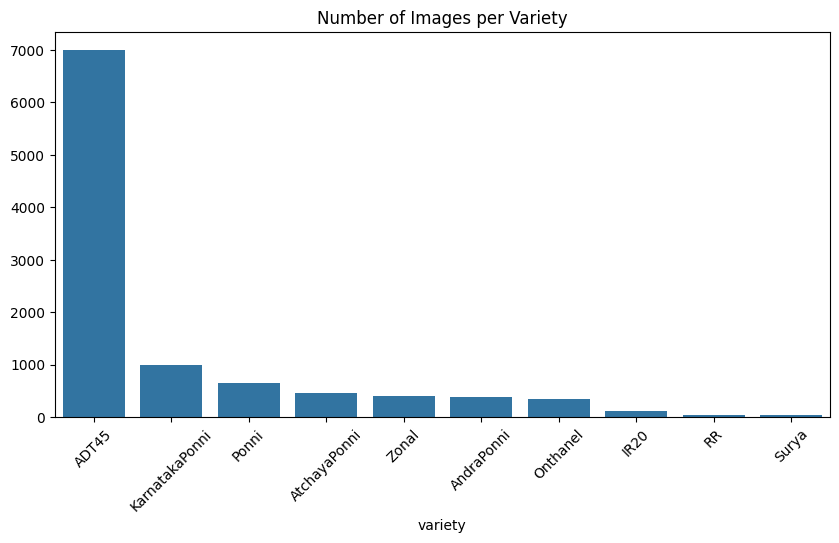

In [7]:
# Variety distribution
variety_counts = meta['variety'].value_counts()

plt.figure(figsize=(10,5))
sns.barplot(x=variety_counts.index, y=variety_counts.values)
plt.title('Number of Images per Variety')
plt.xticks(rotation=45)
plt.show()


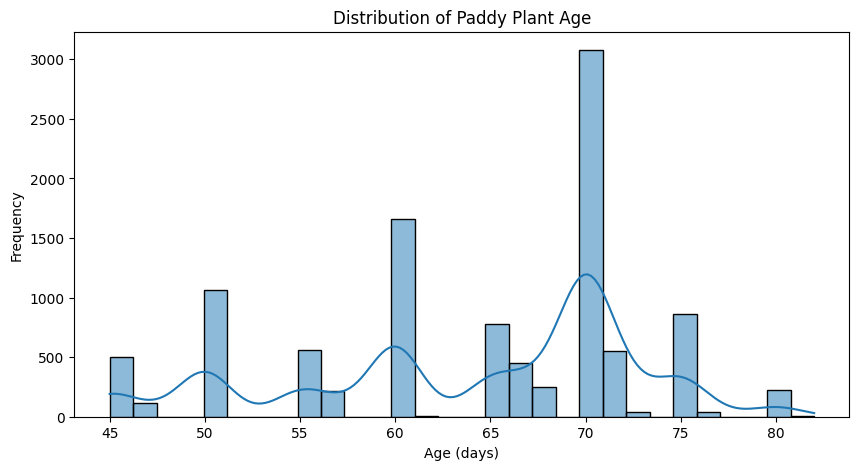

In [8]:
# Age distribution
plt.figure(figsize=(10,5))
sns.histplot(meta['age'], bins=30, kde=True)
plt.title('Distribution of Paddy Plant Age')
plt.xlabel('Age (days)')
plt.ylabel('Frequency')
plt.show()


In [9]:
def find_and_remove_duplicates(folder_path, meta_df):
    seen_hashes = {}
    duplicate_count = 0

    for filename in os.listdir(folder_path):
        file_path = os.path.join(folder_path, filename)

        if not os.path.isfile(file_path):
            continue

        try:
            with Image.open(file_path) as img:
                img_hash = hashlib.md5(img.tobytes()).hexdigest()
        except Exception as e:
            print(f"Skipping non-image or corrupted file: {filename}")
            continue

        if img_hash in seen_hashes:
            print(f"Duplicate found: {filename} (removing)")
            os.remove(file_path)
            meta_df.drop(meta_df[meta_df['image_id'] == filename].index, inplace=True)
            duplicate_count += 1
        else:
            seen_hashes[img_hash] = filename

    print(f"\nRemoved {duplicate_count} duplicate image(s) in {folder_path}")
    return duplicate_count, meta_df


# Read the original file
original_meta_df = pd.read_csv("/content/drive/MyDrive/A2_Machine_Learning/meta_train.csv")

# Make a copy for processing
filtered_meta_df = original_meta_df.copy()

total_duplicates = 0

# Browse each label in the copy
for label in filtered_meta_df['label'].unique():
    folder_path = os.path.join('/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images', label)
    duplicate_count, filtered_meta_df = find_and_remove_duplicates(folder_path, filtered_meta_df)
    total_duplicates += duplicate_count

print(f"\nTotal duplicates removed: {total_duplicates}")

# Save a filtered copy
filtered_meta_df.to_csv("/content/drive/MyDrive/A2_Machine_Learning/meta_train_filtered.csv", index=False)


Duplicate found: 100513.jpg (removing)
Duplicate found: 103032.jpg (removing)
Duplicate found: 104800.jpg (removing)
Duplicate found: 105878.jpg (removing)
Duplicate found: 106984.jpg (removing)
Duplicate found: 107812.jpg (removing)
Duplicate found: 108125.jpg (removing)
Duplicate found: 108353.jpg (removing)

Removed 8 duplicate image(s) in /content/drive/MyDrive/A2_Machine_Learning/train_images/train_images/bacterial_leaf_blight

Removed 0 duplicate image(s) in /content/drive/MyDrive/A2_Machine_Learning/train_images/train_images/bacterial_leaf_streak
Duplicate found: 104803.jpg (removing)

Removed 1 duplicate image(s) in /content/drive/MyDrive/A2_Machine_Learning/train_images/train_images/bacterial_panicle_blight
Duplicate found: 102705.jpg (removing)
Duplicate found: 105626.jpg (removing)
Duplicate found: 105840.jpg (removing)
Duplicate found: 105962.jpg (removing)
Duplicate found: 106520.jpg (removing)
Duplicate found: 107069.jpg (removing)
Duplicate found: 108455.jpg (removing)
D

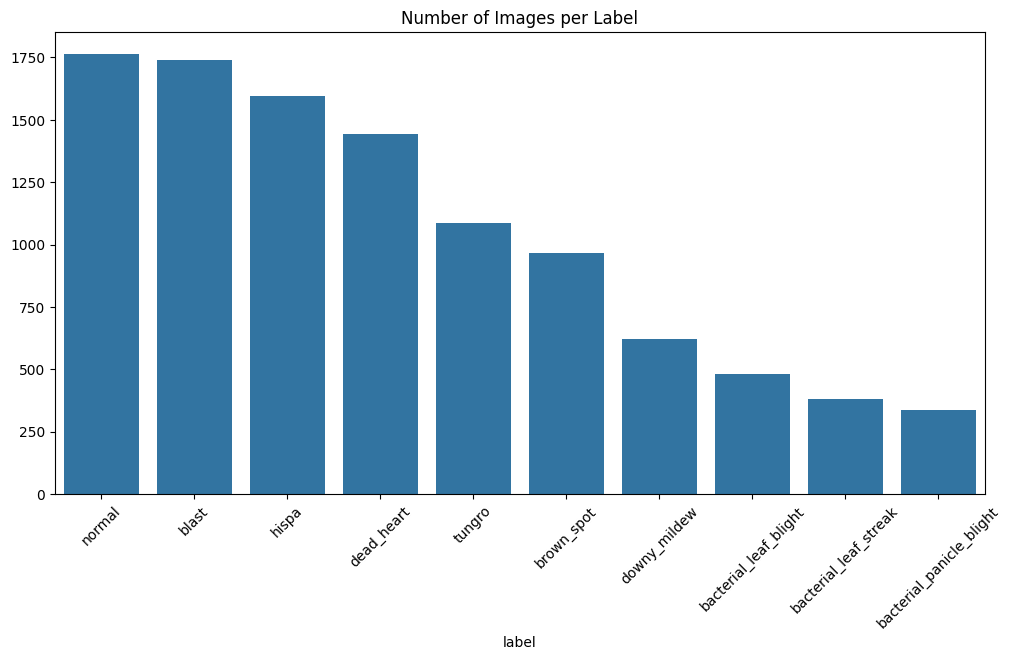

In [10]:
# Recheck the data images of each Label
label_counts = meta['label'].value_counts()

# Plot
plt.figure(figsize=(12,6))
sns.barplot(x=label_counts.index, y=label_counts.values)
plt.title('Number of Images per Label')
plt.xticks(rotation=45)
plt.show()

In [11]:
import os
import numpy as np
import pandas as pd
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, array_to_img

input_dir = "/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images"
output_dir = input_dir

target_augments = {
    "bacterial_panicle_blight": 1030,
    "bacterial_leaf_streak": 1000,
    "bacterial_leaf_blight": 920,
    "downy_mildew": 800,
    "brown_spot": 450,
    "tungro": 300
}

augmentor = ImageDataGenerator(
    rotation_range=25,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

meta_df = pd.read_csv("/content/drive/MyDrive/A2_Machine_Learning/meta_train_filtered.csv")

for label, needed in target_augments.items():
    label_dir = os.path.join(input_dir, label)
    images = [f for f in os.listdir(label_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    count = 0
    i = 0

    while count < needed:
        original_image_name = images[i % len(images)]
        img_path = os.path.join(label_dir, original_image_name)
        img = load_img(img_path)
        x = img_to_array(img)
        x = np.expand_dims(x, axis=0)

        # Augment and save manually
        augmented = next(augmentor.flow(x, batch_size=1))
        new_img = array_to_img(augmented[0])
        new_filename = f"aug_{count}_{original_image_name}"
        new_path = os.path.join(label_dir, new_filename)
        new_img.save(new_path)

        # Append to DataFrame
        try:
            new_row = {
                'image_id': new_filename,
                'label': label,
                'variety': meta_df.loc[meta_df['image_id'] == original_image_name, 'variety'].values[0],
                'age': meta_df.loc[meta_df['image_id'] == original_image_name, 'age'].values[0]
            }
        except IndexError:
            print(f"Warning: Skipping {original_image_name} due to missing metadata.")
            i += 1
            continue

        meta_df = pd.concat([meta_df, pd.DataFrame([new_row])], ignore_index=True)

        count += 1
        i += 1

    print(f"{label}: Created {needed} augmented images.")

# Save the updated metadata
meta_df.to_csv("/content/drive/MyDrive/A2_Machine_Learning/meta_train_filtered.csv", index=False)


bacterial_panicle_blight: Created 1030 augmented images.
bacterial_leaf_streak: Created 1000 augmented images.
bacterial_leaf_blight: Created 920 augmented images.
downy_mildew: Created 800 augmented images.
brown_spot: Created 450 augmented images.
tungro: Created 300 augmented images.


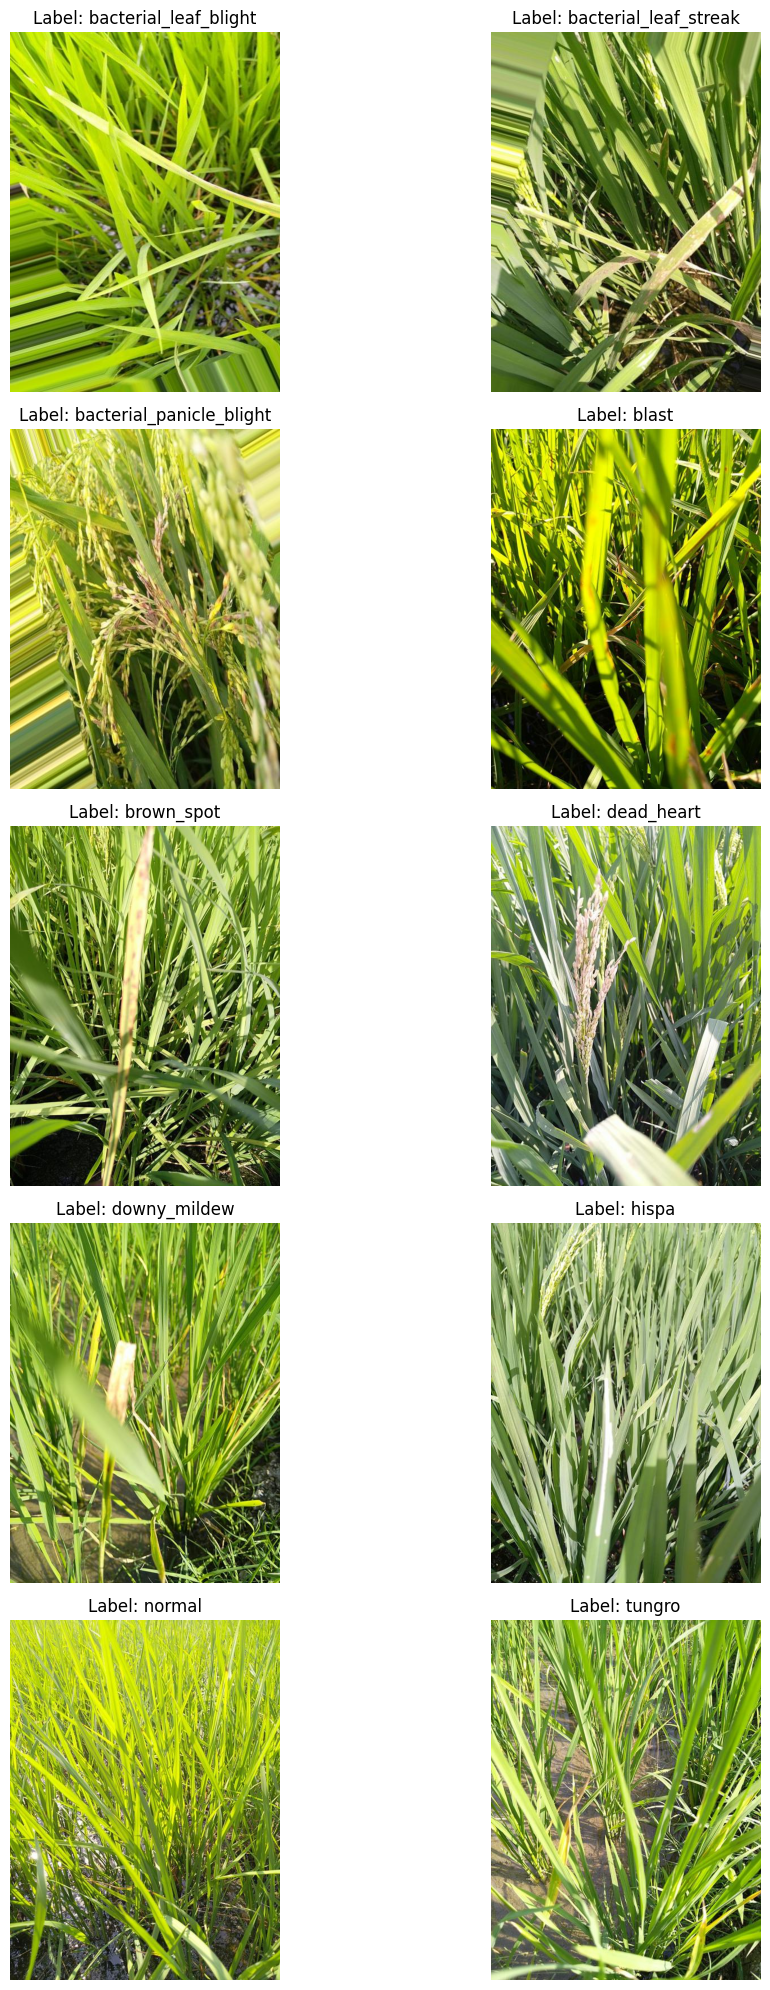

In [12]:
train_path = '/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images'

# Convert labels to lowercase to match folder names
labels = meta['label'].str.lower().unique()

# Plot images
fig, axes = plt.subplots(5,2, figsize=(12,20))
axes = axes.flatten()

for i, label in enumerate(labels):
    img_list = glob(os.path.join(train_path, label, '*.jpg'))

    if len(img_list) == 0:
        print(f"No images found for label {label}. Skipping...")
        continue

    img_path = random.choice(img_list)
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(f"Label: {label}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()


Total number of images checked: 14833
Unique image sizes found: [[480 640]
 [640 480]]
Number of unique sizes: 2


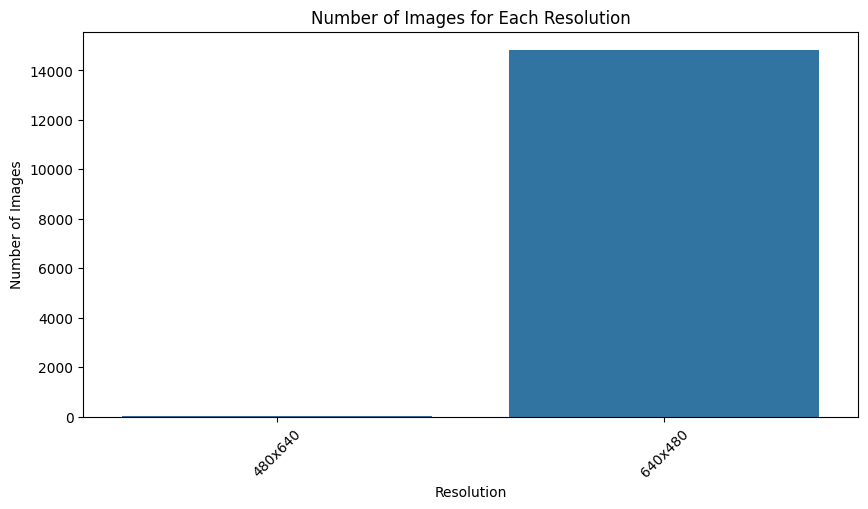


Number of images with wrong resolution: 10
Examples of wrong size images:
/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images/bacterial_leaf_blight/100622.jpg
/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images/bacterial_leaf_blight/103734.jpg
/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images/bacterial_leaf_blight/aug_22_100622.jpg
/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images/bacterial_leaf_blight/aug_176_103734.jpg
/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images/bacterial_leaf_blight/aug_493_100622.jpg
/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images/bacterial_leaf_blight/aug_647_103734.jpg
/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images/brown_spot/103050.jpg
/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images/brown_spot/103343.jpg
/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images/brown_spot/aug_280_103050.jpg
/

In [13]:
train_path = '/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images'

# Lists to store image sizes and file names
image_sizes = []
image_names = []

# Iterate over each disease folder
for label in os.listdir(train_path):
    folder_path = os.path.join(train_path, label)
    img_list = glob(os.path.join(folder_path, '*.jpg'))

    for img_path in img_list:
        img = cv2.imread(img_path)
        if img is not None:
            h, w, c = img.shape
            image_sizes.append((h, w))
            image_names.append(img_path)
        else:
            print(f"Warning: Cannot read image {img_path}")

# Convert to numpy array
image_sizes = np.array(image_sizes)

print(f"Total number of images checked: {len(image_sizes)}")

# Find unique image resolutions
unique_sizes, counts = np.unique(image_sizes, axis=0, return_counts=True)

print(f"Unique image sizes found: {unique_sizes}")
print(f"Number of unique sizes: {len(unique_sizes)}")

# Plot the number of images for each resolution
plt.figure(figsize=(10,5))
sizes_str = [f'{h}x{w}' for h, w in unique_sizes]
sns.barplot(x=sizes_str, y=counts)
plt.title('Number of Images for Each Resolution')
plt.xticks(rotation=45)
plt.xlabel('Resolution')
plt.ylabel('Number of Images')
plt.show()

# If there is more than one resolution, find images that do not match 640x480
expected_size = (640, 480)

if len(unique_sizes) > 1:
    wrong_size_images = []

    for i, (h, w) in enumerate(image_sizes):
        if (h, w) != expected_size:
            wrong_size_images.append(image_names[i])

    print(f"\nNumber of images with wrong resolution: {len(wrong_size_images)}")
    print("Examples of wrong size images:")
    for img in wrong_size_images[:10]:
        print(img)
else:
    print("All images have the correct resolution (640x480).")

    # Extract just filenames from full image paths
wrong_size_filenames = [os.path.basename(path) for path in wrong_size_images]

# Delete incorrectly sized images from disk
for img_path in wrong_size_images:
    try:
        os.remove(img_path)
    except Exception as e:
        print(f"Error deleting {img_path}: {e}")

print(f"\nDeleted {len(wrong_size_filenames)} images with incorrect resolution.")

# Update meta_train_filtered.csv
meta_path = "/content/drive/MyDrive/A2_Machine_Learning/meta_train_filtered.csv"
filtered_meta_df = pd.read_csv(meta_path)

# Remove rows with incorrect image filenames
filtered_meta_df = filtered_meta_df[~filtered_meta_df['image_id'].isin(wrong_size_filenames)]

# Save the updated CSV
filtered_meta_df.to_csv(meta_path, index=False)
print("Updated meta_train_filtered.csv.")


<Figure size 1000x600 with 0 Axes>

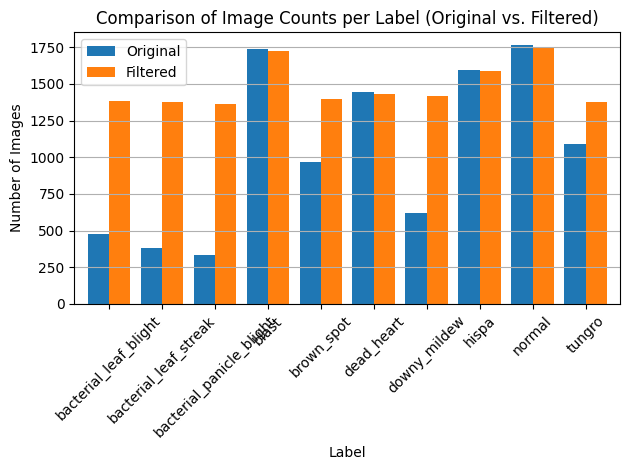

In [14]:
# Load original and filtered metadata
meta_df = pd.read_csv("/content/drive/MyDrive/A2_Machine_Learning/meta_train.csv")
filtered_meta_df = pd.read_csv("/content/drive/MyDrive/A2_Machine_Learning/meta_train_filtered.csv")

# Count labels before and after filtering
original_counts = meta_df['label'].value_counts().sort_index()
filtered_counts = filtered_meta_df['label'].value_counts().sort_index()

# Combine counts into a single DataFrame for comparison
comparison_df = pd.DataFrame({
    'Original': original_counts,
    'Filtered': filtered_counts
}).fillna(0)

# Plot grouped bar chart
plt.figure(figsize=(10, 6))
comparison_df.plot(kind='bar', width=0.8)
plt.title('Comparison of Image Counts per Label (Original vs. Filtered)')
plt.ylabel('Number of Images')
plt.xlabel('Label')
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(axis='y')
plt.show()


In [15]:
# Convert class labels to strings (required when using class_mode='categorical')
filtered_meta_df['label'] = filtered_meta_df['label'].astype(str)

# Add a new column 'ImgPath' that constructs the relative path to each image
filtered_meta_df['ImgPath'] = filtered_meta_df['label'] + '/' + filtered_meta_df['image_id']  # e.g., /blast/100123.jpg

# Stratified split to ensure class distribution remains balanced in train and test sets
train_data, test_data = train_test_split(
    filtered_meta_df,
    test_size=0.2,
    stratify=filtered_meta_df['label'],            # ensures class ratios stay consistent
    random_state=42
)

# ImageDataGenerator for training: apply rescaling and set data format
train_datagen = ImageDataGenerator(
    rescale=1./255,                       # normalize pixel values to [0, 1]
    data_format='channels_last'          # image shape = (height, width, channels)
)

# ImageDataGenerator for validation/test (no augmentation, just rescaling)
val_test_datagen = ImageDataGenerator(
    rescale=1./255,
    data_format='channels_last'
)

# Set common image size and batch size
BATCH_SIZE = 32
IMG_SIZE = (32, 32)  # resizing all input images to 32x32
OUTPUT_CLASSES = 10
# Create generator for training data
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_data,
    directory='/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images',
    x_col='ImgPath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

# Create generator for validation data
val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_data,
    directory='/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images',
    x_col='ImgPath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 11858 validated image filenames belonging to 10 classes.
Found 2965 validated image filenames belonging to 10 classes.


In [16]:
import matplotlib.pyplot as plt
def plot_learning_curve(train_loss, val_loss, train_metric, val_metric, metric_name='Accuracy'):
    plt.figure(figsize=(10,5))

    plt.subplot(1,2,1)
    plt.plot(train_loss, 'r--')
    plt.plot(val_loss, 'b--')
    plt.xlabel("epochs")
    plt.ylabel("Loss")
    plt.legend(['train', 'val'], loc='upper left')

    plt.subplot(1,2,2)
    plt.plot(train_metric, 'r--')
    plt.plot(val_metric, 'b--')
    plt.xlabel("epochs")
    plt.ylabel(metric_name)
    plt.legend(['train', 'val'], loc='upper left')

    plt.show()

In [17]:
# Set common image size and batch size
BATCH_SIZE = 32
IMG_SIZE = (299, 299)  # resizing all input images to 299x299

# Create generator for training data
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_data,
    directory='/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images',
    x_col='ImgPath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

# Create generator for validation data
val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_data,
    directory='/content/drive/MyDrive/A2_Machine_Learning/train_images/train_images',
    x_col='ImgPath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)


Found 11858 validated image filenames belonging to 10 classes.
Found 2965 validated image filenames belonging to 10 classes.


In [18]:
# ──────────────────────────────────────────────────────────────────────────────
# 0) Suppress the “considered legacy” HDF5 warning from absl/Keras
import warnings
warnings.filterwarnings(
    "ignore",
    message=".*considered legacy.*",
    category=UserWarning
)
from absl import logging
logging.set_verbosity(logging.ERROR)
# ──────────────────────────────────────────────────────────────────────────────

from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    BatchNormalization,
    Dropout,
    Dense
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

def build_inceptionv3_scratch(input_shape=(299, 299, 3), num_classes=10):
    base = InceptionV3(weights=None, include_top=False, input_shape=input_shape)
    x = base.output
    x = GlobalAveragePooling2D(name='global_avg_pool')(x)
    x = BatchNormalization(name='bn')(x)
    x = Dropout(0.5, name='dropout')(x)
    outputs = Dense(num_classes, activation='softmax', name='predictions')(x)
    model = Model(inputs=base.input, outputs=outputs, name='InceptionV3_from_scratch')
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# ──────────────────────────────────────────────────────────────────────────────
# Callbacks (save best in HDF5 by virtue of .h5 extension)
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(
        filepath='inceptionv3_task1_best.h5',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]
# ──────────────────────────────────────────────────────────────────────────────

# 5) Build & train
model = build_inceptionv3_scratch(input_shape=(299, 299, 3), num_classes=10)
history = model.fit(
    train_generator,
    epochs=50,
    validation_data=val_generator,
    callbacks=callbacks
)

# ──────────────────────────────────────────────────────────────────────────────
# Save the final model (last‐epoch weights) in HDF5
model.save('inceptionv3_task1_final.h5', save_format='h5')
print("✅ Saved best → inceptionv3_task1_best.h5")
print("✅ Saved final → inceptionv3_task1_final.h5")
# ──────────────────────────────────────────────────────────────────────────────


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
371/371 ━━━━━━━━━━━━━━━━━━━━ 0s 498ms/step - accuracy: 0.3128 - loss: 2.4169
Epoch 1: val_accuracy improved from -inf to 0.11062, saving model to inceptionv3_task1_best.h5
371/371 ━━━━━━━━━━━━━━━━━━━━ 295s 587ms/step - accuracy: 0.3130 - loss: 2.4161 - val_accuracy: 0.1106 - val_loss: 3.7929 - learning_rate: 1.0000e-04
Epoch 2/50
371/371 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.5353 - loss: 1.5753
Epoch 2: val_accuracy improved from 0.11062 to 0.54368, saving model to inceptionv3_task1_best.h5
371/371 ━━━━━━━━━━━━━━━━━━━━ 170s 459ms/step - accuracy: 0.5353 - loss: 1.5751 - val_accuracy: 0.5437 - val_loss: 1.4555 - learning_rate: 1.0000e-04
Epoch 3/50
371/371 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step - accuracy: 0.6455 - loss: 1.1690
Epoch 3: val_accuracy improved from 0.54368 to 0.59123, saving model to inceptionv3_task1_best.h5
371/371 ━━━━━━━━━━━━━━━━━━━━ 170s 457ms/step - accuracy: 0.6455 - loss: 1.1689 - val_accuracy: 0.5912 - val_loss: 1.3944 - learning_rate: 1.0000e-0

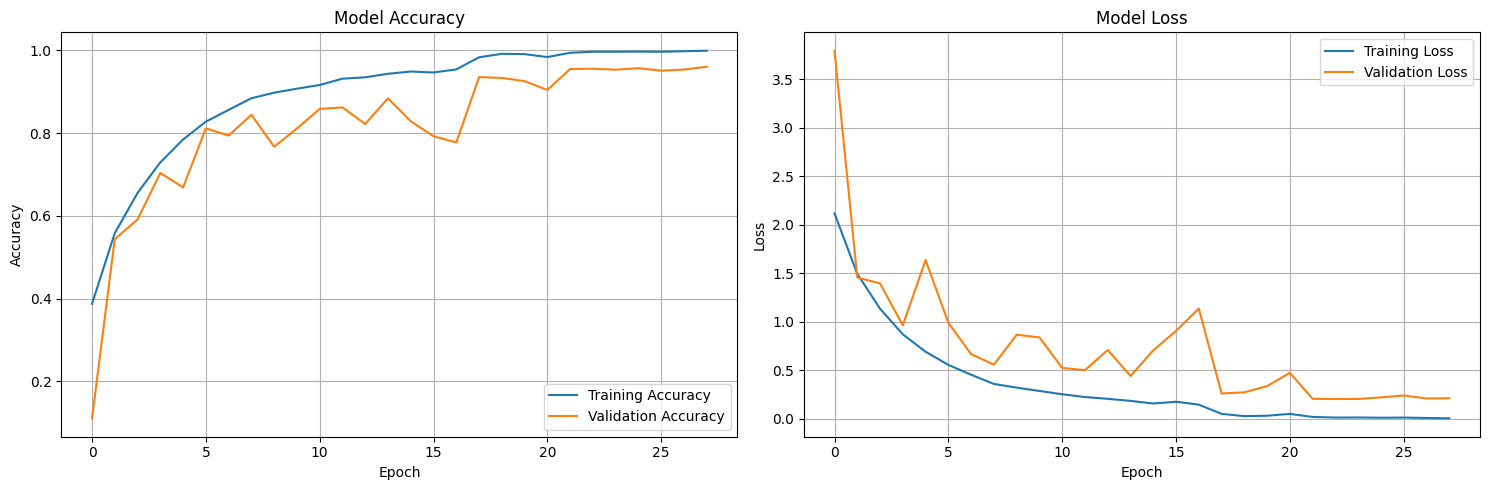

In [19]:
# Plot the learning curves
plt.figure(figsize=(15, 5))

# Plot accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/A2_Machine_Learning/task1_training_curves.png')
plt.show()

In [20]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import os
import numpy as np
import pandas as pd
from google.colab import drive

# Remount drive just in case
drive.mount('/content/drive')

# Use the path we found - Update this path based on the actual location
# Based on the original code, the intended save location might have been the Google Drive path.
# Let's assume the file was saved correctly with the name used in the Checkpoint callback.
model_path = "/content/drive/MyDrive/A2_Machine_Learning/inceptionv3_task1_best.h5"

# Load the model
print(f"Loading model from: {model_path}")
# Add error handling in case the file still doesn't exist
try:
    model = load_model(model_path)
    print("Model loaded successfully!")
except FileNotFoundError:
    print(f"Error: The file {model_path} was not found.")
    print("Please check the path and filename. You can use the find_h5_files function again to verify.")
    # Re-run the find_h5_files function to help debug if needed
    def find_h5_files_debug(directory, max_depth=5):
        h5_files = []
        for root, dirs, files in os.walk(directory):
            depth = root.count(os.sep) - directory.count(os.sep)
            if depth > max_depth:
                continue
            for file in files:
                if file.endswith('.h5'):
                    full_path = os.path.join(root, file)
                    h5_files.append(full_path)
        return h5_files
    print("\nSearching for .h5 files in /content/drive:")
    found_files = find_h5_files_debug('/content/drive', max_depth=5) # Increased depth for debugging
    if found_files:
        print("Found .h5 files:")
        for f in found_files:
            print(f)
    else:
        print("No .h5 files found in /content/drive.")
    raise # Re-raise the error after printing debug info


# Get test image paths
base_dir = "/content/drive/MyDrive/A2_Machine_Learning"
# *** SUGGESTED CHANGE: Update test_dir to point to the actual image folder ***
test_dir = os.path.join(base_dir, "test_images", "test_images") # Assuming images are in a subdirectory

print(f"Using test images from: {test_dir}")

# Check if the test directory exists and contains files
if not os.path.exists(test_dir):
    raise FileNotFoundError(f"Test directory not found: {test_dir}. Please verify the correct path.")
if not os.listdir(test_dir):
     raise FileNotFoundError(f"Test directory is empty: {test_dir}. Please ensure images were extracted correctly.")


test_image_files = [fname for fname in os.listdir(test_dir) if fname.lower().endswith(('.jpg', '.jpeg', '.png'))] # Added more extensions
test_image_paths = [os.path.join(test_dir, fname) for fname in test_image_files]

# Process test images
test_images = []
test_ids = []

# Use InceptionV3 input size (299x299)
target_size = (299, 299)

for path in test_image_paths:
    try:
        # Extract image ID from filename (without extension)
        img_id = os.path.splitext(os.path.basename(path))[0]

        # Load and preprocess image
        img = load_img(path, target_size=target_size)
        img_array = img_to_array(img)
        img_array = img_array / 255.0  # Normalize to [0,1]

        test_images.append(img_array)
        test_ids.append(img_id)
    except Exception as e:
        print(f"Error processing image {path}: {str(e)}")

if not test_images:
    # This check might still be triggered if files exist but none are valid images
    raise ValueError(f"No valid images processed from {test_dir}! Check file types and corruption.")

test_images = np.array(test_images)
print(f"Processed {len(test_images)} test images with shape {test_images.shape}")

# Make predictions
batch_size = 32  # Adjust if needed
print("Making predictions...")
predictions = model.predict(test_images, batch_size=batch_size)
predicted_classes = np.argmax(predictions, axis=1)

# Map class indices back to class names
# Ensure the class indices match the order from train_generator.class_indices
# It's safer to get the class names directly from the generator that was used for training:
# class_names = list(train_generator.class_indices.keys())
# sorted_class_names = sorted(class_names) # Often needed if generator shuffles indices

# If train_generator is not available in this cell, manually verify the order or load it.
# For now, assuming the order is as defined here, but be mindful of the generator's index mapping.
class_names = ['bacterial_leaf_blight', 'bacterial_leaf_streak', 'bacterial_panicle_blight',
               'blast', 'brown_spot', 'dead_heart', 'downy_mildew', 'hispa', 'normal', 'tungro']

predicted_labels = [class_names[idx] for idx in predicted_classes]

# Create DataFrame with predictions
task1_df = pd.DataFrame({
    'image_id': test_ids,
    'label': predicted_labels,
    'variety': [''] * len(test_ids),  # Empty for Task 2
    'age': [''] * len(test_ids)       # Empty for Task 3
})

# Save to CSV
output_path = os.path.join(base_dir, 'task1_prediction.csv')
task1_df.to_csv(output_path, index=False)
print(f"Saved predictions to {output_path} with {len(task1_df)} entries")

# Display a sample of the predictions
print("\nSample predictions:")
print(task1_df.head(10))

# Count predictions by class
print("\nClass distribution in predictions:")
class_counts = task1_df['label'].value_counts()
for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading model from: /content/drive/MyDrive/A2_Machine_Learning/inceptionv3_task1_best.h5
Model loaded successfully!
Using test images from: /content/drive/MyDrive/A2_Machine_Learning/test_images/test_images
Processed 3469 test images with shape (3469, 299, 299, 3)
Making predictions...
109/109 ━━━━━━━━━━━━━━━━━━━━ 26s 184ms/step
Saved predictions to /content/drive/MyDrive/A2_Machine_Learning/task1_prediction.csv with 3469 entries

Sample predictions:
  image_id       label variety age
0   200001       hispa            
1   200002      normal            
2   200003      normal            
3   200004       blast            
4   200005       blast            
5   200006  brown_spot            
6   200007  dead_heart            
7   200008  brown_spot            
8   200009       hispa            
9   200010      normal            

Class distribution in predicti